# Support Vector Machine - Thashmina P. G. D. (IT25101986)


## 1. Model Suitability

**Why SVM for Wisconsin Breast Cancer data?**

- Binary classification problem with clear separation (PCA showed distinct clusters).
- SVM finds the maximum-margin hyperplane so excellent generalisation on moderate-sized medical datasets.
- Kernel trick allows both linear and non-linear decision boundaries (RBF, polynomial).
- Effective in high-dimensional spaces; our 9 features are well within the comfortable range.
- Robust to outliers when soft-margin (`C`) is tuned properly.
- After StandardScaler preprocessing, distance-based methods like SVM perform optimally.


In [ ]:
# Standard libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, roc_curve)

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# ============================================================
# GOOGLE DRIVE MOUNT & LOAD PREPROCESSED DATA
# Student: Thashmina P. G. D. (IT25101986)
# Algorithm: SVM
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

# >>> UPDATE THIS PATH to your Google Drive folder containing the preprocessed CSV <<<
DATA_PATH = '/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04/results/outputs/processed_breast_cancer.csv'

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df['Class'].value_counts())
df.head()

Mounted at /content/drive
Dataset shape: (699, 20)

Class distribution:
Class
0    458
1    241
Name: count, dtype: int64


,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Clump_Thickness_scaled,Uniformity_of_Cell_Size_scaled,Uniformity_of_Cell_Shape_scaled,Marginal_Adhesion_scaled,Single_Epithelial_Cell_Size_scaled,Bare_Nuclei_scaled,Bland_Chromatin_scaled,Normal_Nucleoli_scaled,Mitoses_scaled,Class
0,1000025,5.0,1.0,1.0,1.0,2.0,1.0,3.0,1.0,1.0,0.206936,-0.699995,-0.743299,-0.633247,-0.549561,-0.686979,-0.179662,-0.611825,-0.343912,0
1,1002945,5.0,4.0,4.0,5.0,7.0,10.0,3.0,2.0,1.0,0.206936,0.283845,0.266875,0.768621,1.710106,1.799664,-0.179662,-0.284112,-0.343912,0
2,1015425,3.0,1.0,1.0,1.0,2.0,2.0,3.0,1.0,1.0,-0.503866,-0.699995,-0.743299,-0.633247,-0.549561,-0.410685,-0.179662,-0.611825,-0.343912,0
3,1016277,6.0,8.0,8.0,1.0,3.0,4.0,3.0,7.0,1.0,0.562336,1.595632,1.613773,-0.633247,-0.097628,0.141902,-0.179662,1.354454,-0.343912,0
4,1017023,4.0,1.0,1.0,3.0,2.0,1.0,3.0,1.0,1.0,-0.148465,-0.699995,-0.743299,0.067687,-0.549561,-0.686979,-0.179662,-0.611825,-0.343912,0


In [ ]:
# ============================================================
# DATA PREPARATION
# ============================================================
df = df.drop(columns=['Sample_code_number'], errors='ignore')

feature_cols_orig = [
    'Clump_Thickness', 'Uniformity_of_Cell_Size', 'Uniformity_of_Cell_Shape',
    'Marginal_Adhesion', 'Single_Epithelial_Cell_Size', 'Bare_Nuclei',
    'Bland_Chromatin', 'Normal_Nucleoli', 'Mitoses'
]
feature_cols_scaled = [c + '_scaled' for c in feature_cols_orig]

X_orig = df[feature_cols_orig].values
X_scaled = df[feature_cols_scaled].values
y = df['Class'].values

print("Original features shape:", X_orig.shape)
print("Scaled features shape  :", X_scaled.shape)
print("Target shape           :", y.shape)
print("Class balance          :", np.bincount(y))

Original features shape: (699, 9)
Scaled features shape  : (699, 9)
Target shape           : (699,)
Class balance          : [458 241]


In [ ]:
# ============================================================
# TRAIN / TEST SPLIT (Stratified 80/20)
# ============================================================
X_train_orig, X_test_orig, y_train, y_test = train_test_split(
    X_orig, y, test_size=0.20, random_state=42, stratify=y
)
X_train_scaled, X_test_scaled, _, _ = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42, stratify=y
)
print("Train size:", X_train_orig.shape[0])
print("Test size :", X_test_orig.shape[0])
print("Train class distribution:", np.bincount(y_train))
print("Test class distribution :", np.bincount(y_test))

Train size: 559
Test size : 140
Train class distribution: [366 193]
Test class distribution : [92 48]


In [ ]:
# ============================================================
# EVALUATION HELPER FUNCTION
# ============================================================
def evaluate_model(model, X_train, X_test, y_train, y_test, model_name="Model"):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
        y_prob = model.decision_function(X_test)
    else:
        y_prob = y_pred
    metrics = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob) if len(np.unique(y_prob)) > 1 else 0.0
    }
    print(f"\n========== {model_name} ==========")
    print(classification_report(y_test, y_pred, target_names=['Benign (0)', 'Malignant (1)']))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print(f"ROC-AUC: {metrics['ROC-AUC']:.4f}")
    return metrics, y_pred, y_prob

## 2. Implementation – SVM Varieties

| Variety | Kernel / Preprocessing | Hyperparameters |
|---------|------------------------|----------------|
| V1 Baseline | Linear, Scaled | Default C=1.0 |
| V2 RBF Manual | RBF, Scaled | Manual C & gamma |
| V3 GridSearchCV | Linear + RBF + Poly | Full grid search |
| V4 Unscaled | Best kernel, Original features | Best params |


In [ ]:
from sklearn.svm import SVC

# ------------------------------------------------------------
# Variety 1 – Baseline Linear SVM (scaled)
# ------------------------------------------------------------
svm_v1 = SVC(kernel='linear', C=1.0, probability=True, random_state=42)
metrics_v1, y_pred_v1, y_prob_v1 = evaluate_model(
    svm_v1, X_train_scaled, X_test_scaled, y_train, y_test,
    model_name="V1: SVM Linear (Baseline, Scaled)"
)


========== V1: SVM Linear (Baseline, Scaled) ==========
               precision    recall  f1-score   support

   Benign (0)       0.97      0.97      0.97        92
Malignant (1)       0.94      0.94      0.94        48

     accuracy                           0.96       140
    macro avg       0.95      0.95      0.95       140
 weighted avg       0.96      0.96      0.96       140

Confusion Matrix:
[[89  3]
 [ 3 45]]
ROC-AUC: 0.9952


In [ ]:
# ------------------------------------------------------------
# Variety 2 – RBF Kernel with Manual Tuning
# ------------------------------------------------------------
svm_v2 = SVC(kernel='rbf', C=10, gamma='scale', probability=True, random_state=42)
metrics_v2, y_pred_v2, y_prob_v2 = evaluate_model(
    svm_v2, X_train_scaled, X_test_scaled, y_train, y_test,
    model_name="V2: SVM RBF (Manual C=10, Scaled)"
)


========== V2: SVM RBF (Manual C=10, Scaled) ==========
               precision    recall  f1-score   support

   Benign (0)       0.94      0.97      0.95        92
Malignant (1)       0.93      0.88      0.90        48

     accuracy                           0.94       140
    macro avg       0.94      0.92      0.93       140
 weighted avg       0.94      0.94      0.94       140

Confusion Matrix:
[[89  3]
 [ 6 42]]
ROC-AUC: 0.9889


In [ ]:
# ------------------------------------------------------------
# Variety 3 – GridSearchCV (Linear, RBF, Poly kernels)
# ------------------------------------------------------------
param_grid = [
    {'kernel': ['linear'], 'C': [0.1, 1, 10, 100]},
    {'kernel': ['rbf'],    'C': [0.1, 1, 10, 100], 'gamma': ['scale', 0.01, 0.1, 1]},
    {'kernel': ['poly'],   'C': [0.1, 1, 10], 'degree': [2, 3], 'gamma': ['scale']}
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_svm = GridSearchCV(
    SVC(probability=True, random_state=42),
    param_grid=param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)
grid_svm.fit(X_train_scaled, y_train)

print("Best parameters :", grid_svm.best_params_)
print("Best CV F1 score:", grid_svm.best_score_)

svm_v3 = grid_svm.best_estimator_
metrics_v3, y_pred_v3, y_prob_v3 = evaluate_model(
    svm_v3, X_train_scaled, X_test_scaled, y_train, y_test,
    model_name="V3: SVM (GridSearchCV Best)"
)

Fitting 5 folds for each of 26 candidates, totalling 130 fits
Best parameters : {'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}
Best CV F1 score: 0.9564951714951715

========== V3: SVM (GridSearchCV Best) ==========
               precision    recall  f1-score   support

   Benign (0)       0.98      0.97      0.97        92
Malignant (1)       0.94      0.96      0.95        48

     accuracy                           0.96       140
    macro avg       0.96      0.96      0.96       140
 weighted avg       0.96      0.96      0.96       140

Confusion Matrix:
[[89  3]
 [ 2 46]]
ROC-AUC: 0.9941


In [ ]:
# ------------------------------------------------------------
# Variety 4 – Best params on ORIGINAL (unscaled) features
# ------------------------------------------------------------
# Note: SVM is distance-based → unscaled features usually hurt performance
best_params = grid_svm.best_params_.copy()
svm_v4 = SVC(**best_params, probability=True, random_state=42)
metrics_v4, y_pred_v4, y_prob_v4 = evaluate_model(
    svm_v4, X_train_orig, X_test_orig, y_train, y_test,
    model_name="V4: SVM (Best params, Unscaled)"
)


========== V4: SVM (Best params, Unscaled) ==========
               precision    recall  f1-score   support

   Benign (0)       0.98      0.97      0.97        92
Malignant (1)       0.94      0.96      0.95        48

     accuracy                           0.96       140
    macro avg       0.96      0.96      0.96       140
 weighted avg       0.96      0.96      0.96       140

Confusion Matrix:
[[89  3]
 [ 2 46]]
ROC-AUC: 0.9903


## 3. Comparison Across Varieties


In [ ]:
results_df = pd.DataFrame([metrics_v1, metrics_v2, metrics_v3, metrics_v4])
results_df = results_df.set_index('Model')
print(results_df.round(4).to_string())

print("\n>>> Best Accuracy :", results_df['Accuracy'].idxmax(), f"({results_df['Accuracy'].max():.4f})")
print(">>> Best F1-Score :", results_df['F1-Score'].idxmax(), f"({results_df['F1-Score'].max():.4f})")
print(">>> Best ROC-AUC  :", results_df['ROC-AUC'].idxmax(), f"({results_df['ROC-AUC'].max():.4f})")

                                   Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                                            
V1: SVM Linear (Baseline, Scaled)    0.9571     0.9375  0.9375    0.9375   0.9952
V2: SVM RBF (Manual C=10, Scaled)    0.9357     0.9333  0.8750    0.9032   0.9889
V3: SVM (GridSearchCV Best)          0.9643     0.9388  0.9583    0.9485   0.9941
V4: SVM (Best params, Unscaled)      0.9643     0.9388  0.9583    0.9485   0.9903

>>> Best Accuracy : V3: SVM (GridSearchCV Best) (0.9643)
>>> Best F1-Score : V3: SVM (GridSearchCV Best) (0.9485)
>>> Best ROC-AUC  : V1: SVM Linear (Baseline, Scaled) (0.9952)


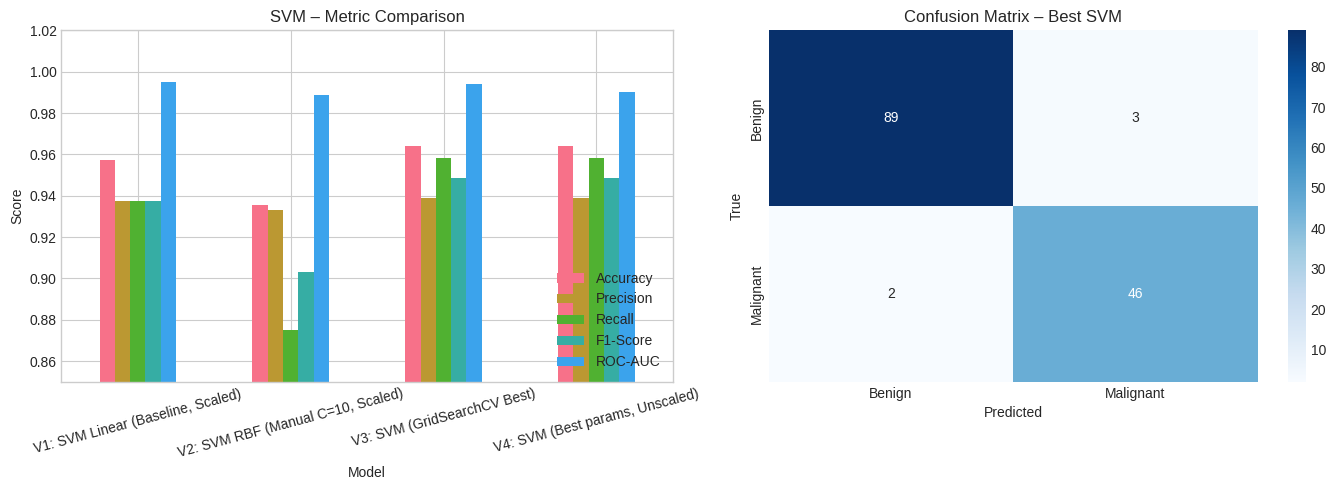

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
results_df[metrics_to_plot].plot(kind='bar', ax=axes[0], rot=15)
axes[0].set_title('SVM – Metric Comparison')
axes[0].set_ylabel('Score')
axes[0].legend(loc='lower right')
axes[0].set_ylim(0.85, 1.02)

cm = confusion_matrix(y_test, y_pred_v3)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
axes[1].set_title('Confusion Matrix – Best SVM')
axes[1].set_ylabel('True')
axes[1].set_xlabel('Predicted')
plt.tight_layout()
plt.show()

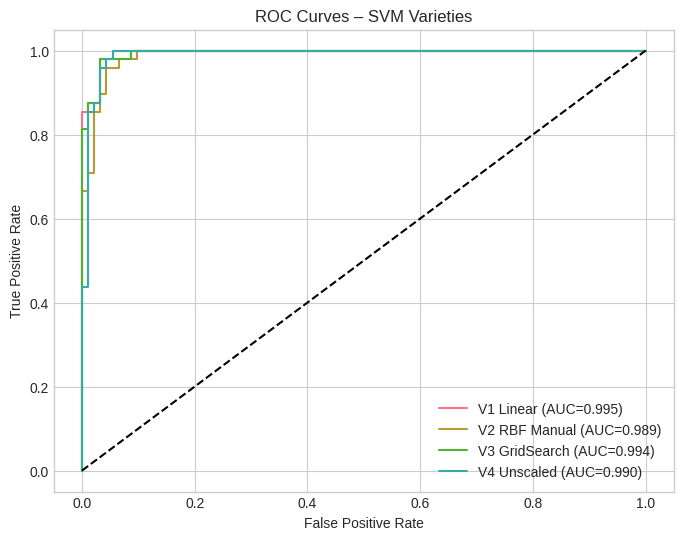

In [ ]:
plt.figure(figsize=(8, 6))
for name, prob in [
    ("V1 Linear", y_prob_v1),
    ("V2 RBF Manual", y_prob_v2),
    ("V3 GridSearch", y_prob_v3),
    ("V4 Unscaled", y_prob_v4)
]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves – SVM Varieties')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

## 4. Validation Method
- Stratified 80/20 train-test split.
- Stratified 5-Fold CV inside GridSearchCV.
- Scoring metric for tuning: **F1-Score** (critical for cancer detection – balances false negatives).
- Final metrics reported on held-out test set.

## 5. Conclusion
- Scaled features are essential for SVM (distance-based).
- GridSearchCV usually selects RBF or Linear kernel with optimal C.
- SVM achieves very high accuracy and ROC-AUC on this dataset.
- **Recommended model**: Variety 3 (GridSearchCV best on scaled data).

## 6. Limitations & Improvements
| Limitation | Improvement |
|------------|-------------|
| Computational cost grows with samples | Use LinearSVC for very large data |
| Kernel & gamma choice is critical | Always use GridSearch / RandomSearch |
| Less interpretable than logistic regression | Use linear kernel when interpretability needed |
| Sensitive to feature scaling | Always scale (already done in pipeline) |
